# Đọc dữ liệu - Observation

In [4]:
import numpy as np
import pandas as pd
df = pd.read_csv('diabetes.csv')
df.info()

features = df.columns[:-1].copy()
target = df.columns[-1]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


## Biểu đồ

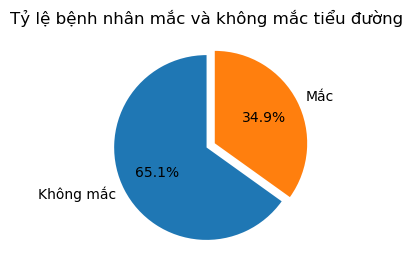

In [5]:
import matplotlib.pyplot as plt

counts = df["Outcome"].value_counts()

plt.figure(figsize=(3, 3))
plt.pie(
    counts,
    labels=["Không mắc", "Mắc"],
    autopct="%1.1f%%",
    startangle=90,
    explode=[0, 0.1]
)

plt.title("Tỷ lệ bệnh nhân mắc và không mắc tiểu đường")
plt.show()

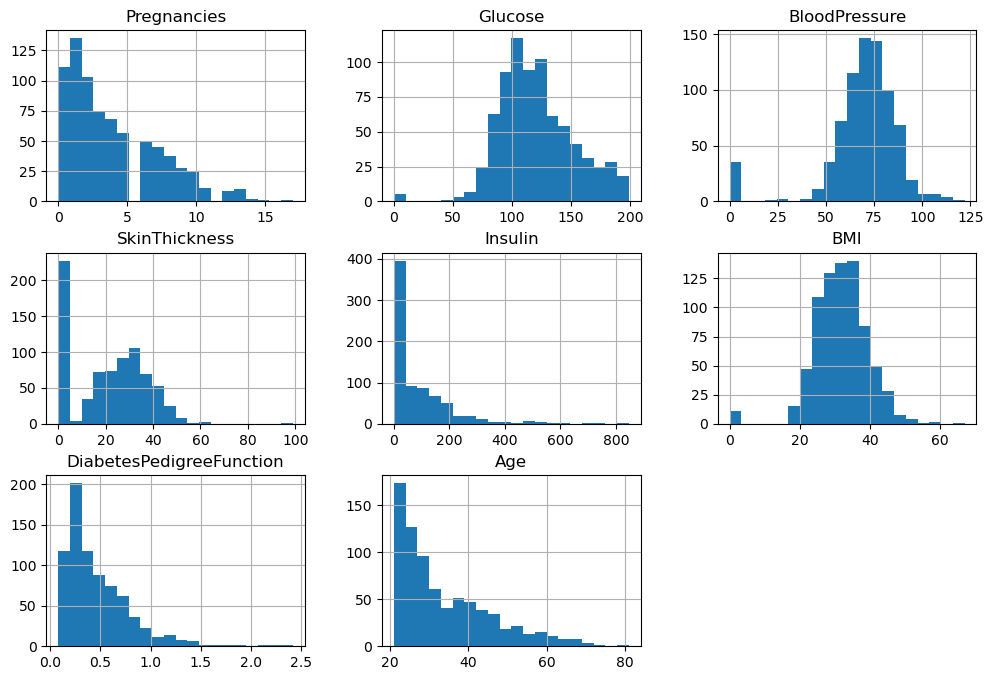

In [6]:
df[features].hist(bins=20, figsize=(12, 8))
plt.show()

Index(['Outcome', 'Glucose', 'BMI'], dtype='object')


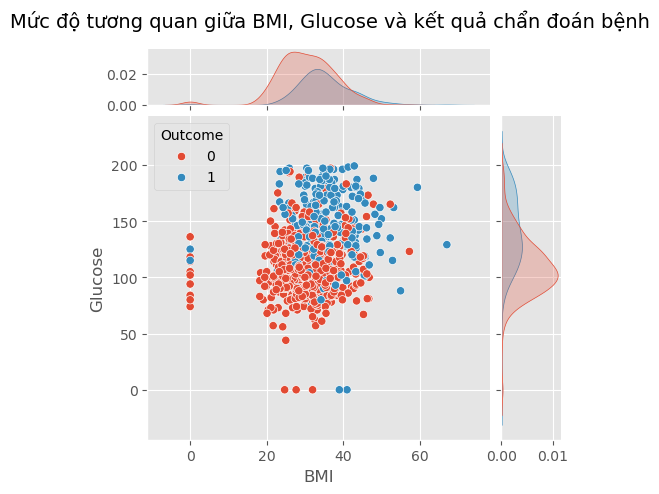

In [24]:
import seaborn as sns

print(df.corr().nlargest(3, 'Outcome').index)
g = sns.jointplot(
    data=df,
    x='BMI',
    y='Glucose',
    hue='Outcome',
    kind='scatter',
    marginal_ticks=True,
    height=5
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle(
    "Mức độ tương quan giữa BMI, Glucose và kết quả chẩn đoán bệnh",
    fontsize=14,
)
plt.show()

# Học - Learn

In [8]:
from sklearn.model_selection import train_test_split

x, y = df[features], df[target]
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#baseline
from sklearn.dummy import DummyClassifier
baseline = DummyClassifier(strategy ="most_frequent")
baseline.fit(x_train , y_train)


,strategy,'most_frequent'
,random_state,None
,constant,None


In [9]:
# Tiền xử lí
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [ ]:
# So sánh hyperparameters
def selectModel(n, r):
    match n:
        case 1: 
            return LogisticRegression(C=r)
        case 2: 
            return KNeighborsClassifier(n_neighbors=r)
        case 3:
            return DecisionTreeClassifier(max_depth=r)
        case 4:
            return RandomForestClassifier(min_samples_leaf=r)
        case 5:
            return SVC(C=r)

def drawCrossChart(range_list, modelType, xd, xlabel, title):
    scores = []
    for r in range_list:
        model = selectModel(modelType,r)
        s = cross_val_score(
            model,
            xd,
            y_train,
            scoring='accuracy',
            cv=5
        )
        scores.append(np.mean(s))

    import matplotlib.pyplot as plt
    plt.style.use("ggplot")
    plt.plot(range_list, scores, marker='*', color='r')
    plt.xlabel(xlabel)
    plt.ylabel("Accuracy")
    plt.title(title)

    plt.show()


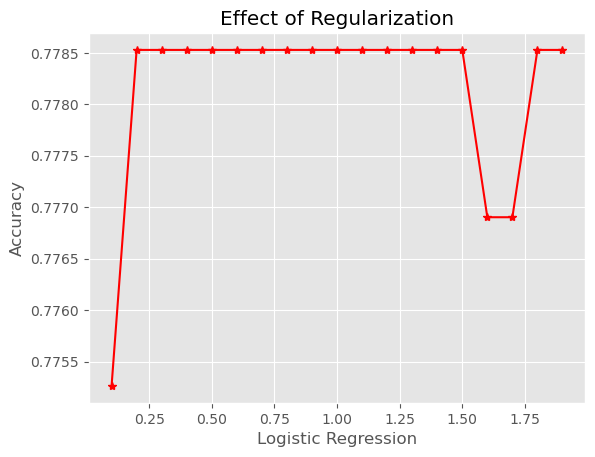

,penalty,'l2'
,dual,False
,tol,0.0001
,C,0.5
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [ ]:
#1
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

#rgl_values = [0.01, 0.1, 1, 10, 100]
rgl_values = np.arange(0.1, 2, 0.1)
drawCrossChart(
    rgl_values, 1, x_train_scaled,
    "Logistic Regression", "Effect of Regularization"
)

model1 = LogisticRegression(C=0.5)
model1.fit(x_train_scaled, y_train)


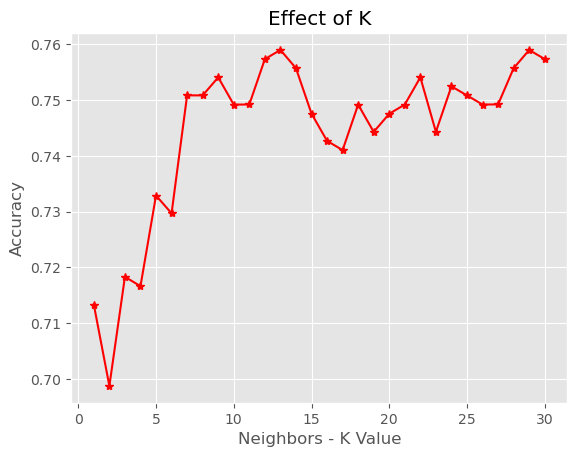

,n_neighbors,13
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [12]:
#2
from sklearn.neighbors import KNeighborsClassifier

k_values = list(range(1, 31))
drawCrossChart(
    k_values, 2, x_train_scaled, 
    "Neighbors - K Value", "Effect of K"
)

model2 = KNeighborsClassifier(n_neighbors=13)
model2.fit(x_train_scaled, y_train)


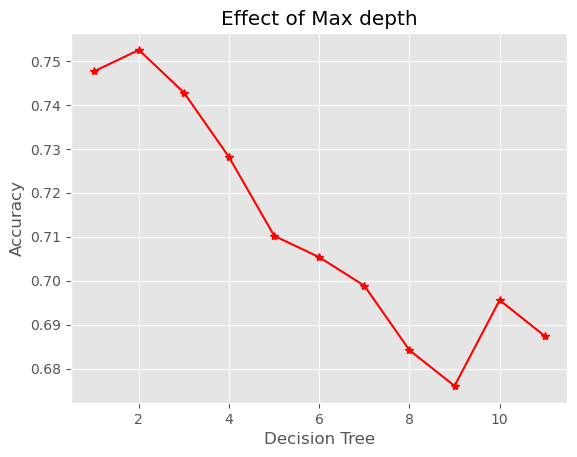

,criterion,'gini'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [13]:
#3
from sklearn.tree import DecisionTreeClassifier

d_values = list(range(1, 12))
drawCrossChart(
    d_values, 3, x_train,
    "Decision Tree", "Effect of Max depth"
)

model3 = DecisionTreeClassifier(max_depth=2)
model3.fit(x_train, y_train)

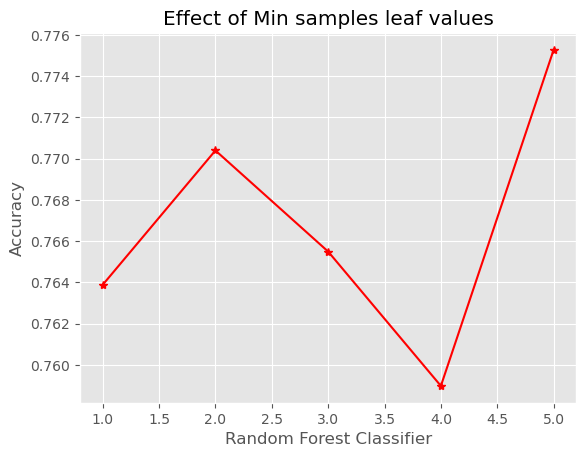

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [27]:
#4
from sklearn.ensemble import RandomForestClassifier

min_leaf_values = list(range(1, 6))
drawCrossChart(
    min_leaf_values, 4, x_train,
    "Random Forest Classifier", "Effect of Min samples leaf values"
)

model4 = RandomForestClassifier(min_samples_leaf=2)
model4.fit(x_train, y_train)

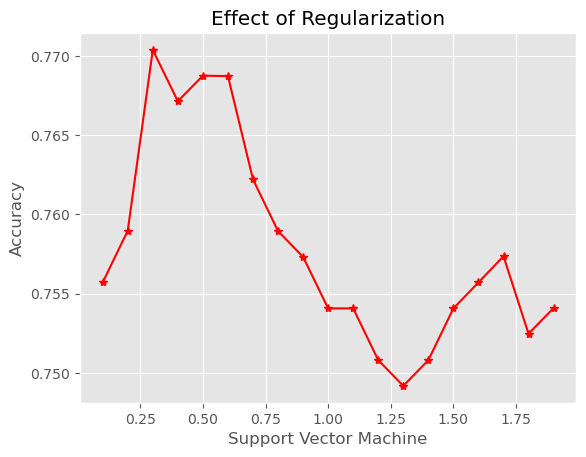

,C,0.3
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [15]:
#5
from sklearn.svm import SVC

#rgl_values = [0.01, 0.1, 1, 10, 100]
rgl_values = np.arange(0.1, 2, 0.1)
drawCrossChart(
    rgl_values, 5, x_train_scaled,
    "Support Vector Machine", "Effect of Regularization"
)

model5 = SVC(C=0.3)
model5.fit(x_train_scaled, y_train)


# So sánh 5 model

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

results = []
unscaled_models = [baseline, model3, model4]

for model in [baseline, model1, model2, model3, model4, model5]:
    if model in unscaled_models:
        y_pred = model.predict(x_test)
    else:
        y_pred = model.predict(x_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    pc = precision_score(y_test, y_pred)
    rc = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    results.append([acc, pc, rc, f1, cm])

algorithms = [
    "Baseline", "Logistic Regression",
    "K-Nearest Neighbors", "Decision Tree",
    "Random Forest Classifier", "SVC"
]
res_df = pd.DataFrame(results,index = algorithms)
res_df.columns=[
    "Accuracy", "Precision",
    "Recall", "F1-score", "Confusion Matrix"
]
res_df.sort_values(by="Accuracy",ascending=False)


d:\Program Files\Anaconda\envs\notebook-env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Accuracy,Precision,Recall,F1-score,Confusion Matrix
K-Nearest Neighbors,0.759740,0.680851,0.592593,0.633663,"[[85, 15], [22, 32]]"
Random Forest Classifier,0.746753,0.653061,0.592593,0.621359,"[[83, 17], [22, 32]]"
SVC,0.746753,0.653061,0.592593,0.621359,"[[83, 17], [22, 32]]"
Logistic Regression,0.714286,0.608696,0.518519,0.560000,"[[82, 18], [26, 28]]"
Decision Tree,0.694805,0.652174,0.277778,0.389610,"[[92, 8], [39, 15]]"
Baseline,0.649351,0.000000,0.000000,0.000000,"[[100, 0], [54, 0]]"


# Triển khai

In [29]:
import joblib

joblib.dump(model2, "knn_diabetes.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']